# Task 3 — Strategic Recommendation Proposal: portfolio analysis

Client: **Summit Investments** (hypothetical) — Equities 45% · Fixed Income 30% · Real Estate 15% · Cash 10%.
Priorities (in order): **diversification, risk mitigation, sustainability, moderate growth, long-term stability.**

This notebook reproduces every number, table and chart in `Strategic_Recommendation_Proposal.tex`:

1. Current vs. proposed allocation, and a check of the client's targets → `figures/table1_allocation.tex`, `figures/fig1_allocation.pdf`
2. Expected return, volatility and diversification → `figures/table2_metrics.tex`
3. Where the risk comes from (risk contribution) → `figures/fig2_risk_contribution.pdf`
4. Stress tests for the client's three concerns → `figures/table3_stress.tex`, `figures/fig3_stress.pdf`

> **Assumptions.** The Client Profile gives weights but no return data, so expected returns, volatilities,
> correlations and stress shocks below are **illustrative long-run assumptions** in line with typical
> capital-market assumptions. They are stated in one place so they can be changed and the whole analysis re-run.
> Results show *direction and trade-offs*, not a forecast.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG = Path("figures"); FIG.mkdir(exist_ok=True)

# Two-series palette (validated: lightness, chroma, CVD separation, normal-vision floor)
CUR, PRO = "#D9822B", "#2A55B0"   # current = orange, proposed = blue
INK, MUTED = "#222222", "#666666"
plt.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#BBBBBB", "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED})

def tex(v, fmt="{:.1f}", sign=False):
    s = (("{:+" + fmt[2:]) if sign else fmt).format(v)
    return s.replace("-", r"\textminus{}")

## 1. Allocations

The current fixed-income sleeve (30%) is corporate bonds and Treasuries. The proposal keeps 30% in fixed income but
splits it into **shorter-duration** core bonds (rising rates are a stated concern), **green bonds** and **emerging-market bonds**.
US large-cap equities are cut from 45% to 29% to fund international, green and ESG exposure.

In [2]:
ASSETS = ["US large-cap equities", "International equities ETF", "Green ETFs",
          "ESG mutual fund", "Corporate & Treasury bonds", "Green bonds",
          "Emerging market bonds", "REITs", "Cash"]

current  = pd.Series([45, 0, 0, 0, 30, 0, 0, 15, 10], index=ASSETS, dtype=float)
proposed = pd.Series([27, 5, 7, 6, 22, 4, 6, 13, 10], index=ASSETS, dtype=float)
assert current.sum() == 100 and proposed.sum() == 100

alloc = pd.DataFrame({"Current (%)": current, "Proposed (%)": proposed})
alloc["Change (pts)"] = alloc["Proposed (%)"] - alloc["Current (%)"]
alloc

,Current (%),Proposed (%),Change (pts)
US large-cap equities,45.0,27.0,-18.0
International equities ETF,0.0,5.0,5.0
Green ETFs,0.0,7.0,7.0
ESG mutual fund,0.0,6.0,6.0
Corporate & Treasury bonds,30.0,22.0,-8.0
Green bonds,0.0,4.0,4.0
Emerging market bonds,0.0,6.0,6.0
REITs,15.0,13.0,-2.0
Cash,10.0,10.0,0.0


In [3]:
# Check the client's stated targets (Client Profile Reference Sheet)
sustainable_funds = proposed[["Green ETFs", "ESG mutual fund"]].sum()
sustainable_all   = proposed[["Green ETFs", "ESG mutual fund", "Green bonds"]].sum()
em_bonds          = proposed["Emerging market bonds"]
non_us            = proposed[["International equities ETF", "Emerging market bonds"]].sum()
checks = pd.DataFrame({
    "Target": ["Green ETFs + ESG funds >= 10%", "Emerging market bonds <= 8%",
               "Less reliance on US large-cap", "More international assets"],
    "Proposed": [f"{sustainable_funds:.0f}%", f"{em_bonds:.0f}%",
                 f"{current['US large-cap equities']:.0f}% -> {proposed['US large-cap equities']:.0f}%",
                 f"0% -> {non_us:.0f}%"],
    "Met": [sustainable_funds >= 10, em_bonds <= 8,
            proposed["US large-cap equities"] < current["US large-cap equities"], non_us > 0],
})
assert checks["Met"].all()
print(f"Total sustainable allocation incl. green bonds: {sustainable_all:.0f}%")
checks

Total sustainable allocation incl. green bonds: 17%


,Target,Proposed,Met
0,Green ETFs + ESG funds >= 10%,13%,True
1,Emerging market bonds <= 8%,6%,True
2,Less reliance on US large-cap,45% -> 27%,True
3,More international assets,0% -> 11%,True


In [4]:
# LaTeX table for the proposal
lines = [r"\begin{tabular}{@{}lrrr@{}}", r"\toprule",
         r"\textbf{Holding} & \textbf{Current} & \textbf{Proposed} & \textbf{Change} \\", r"\midrule"]
for a, r in alloc.iterrows():
    ch = "---" if r["Change (pts)"] == 0 else tex(r["Change (pts)"], "{:.0f}", sign=True)
    lines.append(f"{a.replace('&', chr(92) + '&')} & {r['Current (%)']:.0f}\\% & {r['Proposed (%)']:.0f}\\% & {ch} \\\\")
lines += [r"\midrule", r"\textbf{Total} & 100\% & 100\% & \\", r"\bottomrule", r"\end{tabular}"]
(FIG / "table1_allocation.tex").write_text("\n".join(lines))
print("\n".join(lines))

\begin{tabular}{@{}lrrr@{}}
\toprule
\textbf{Holding} & \textbf{Current} & \textbf{Proposed} & \textbf{Change} \\
\midrule
US large-cap equities & 45\% & 27\% & \textminus{}18 \\
International equities ETF & 0\% & 5\% & +5 \\
Green ETFs & 0\% & 7\% & +7 \\
ESG mutual fund & 0\% & 6\% & +6 \\
Corporate \& Treasury bonds & 30\% & 22\% & \textminus{}8 \\
Green bonds & 0\% & 4\% & +4 \\
Emerging market bonds & 0\% & 6\% & +6 \\
REITs & 15\% & 13\% & \textminus{}2 \\
Cash & 10\% & 10\% & --- \\
\midrule
\textbf{Total} & 100\% & 100\% & \\
\bottomrule
\end{tabular}


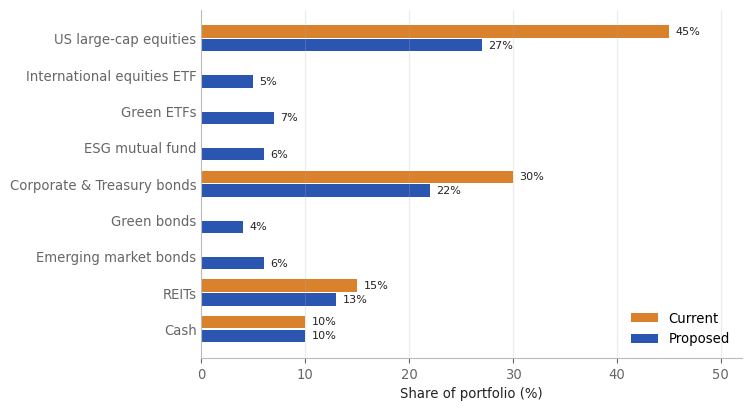

In [5]:
fig, ax = plt.subplots(figsize=(7.6, 4.2))
y = np.arange(len(ASSETS)); h = 0.38
for vals, off, col, lab in [(current, -h/2, CUR, "Current"), (proposed, h/2, PRO, "Proposed")]:
    bars = ax.barh(y + off, vals, height=h - 0.04, color=col, label=lab)
    for b, v in zip(bars, vals):
        if v > 0:
            ax.text(v + 0.6, b.get_y() + b.get_height()/2, f"{v:.0f}%", va="center", fontsize=8, color=INK)
ax.set_yticks(y, ASSETS); ax.invert_yaxis()
ax.set_xlabel("Share of portfolio (%)"); ax.set_xlim(0, 52)
ax.grid(axis="x", alpha=0.25); ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig1_allocation.pdf", bbox_inches="tight")
plt.show()

## 2. Expected return, volatility and diversification

Illustrative annual assumptions (%), and a correlation matrix built from asset-class groups.

In [6]:
cma = pd.DataFrame({
    #                              exp. return  volatility
    "US large-cap equities":       [7.0, 16.0],
    "International equities ETF":  [7.0, 17.0],
    "Green ETFs":                  [8.5, 24.0],
    "ESG mutual fund":             [5.5, 10.0],
    "Corporate & Treasury bonds":  [4.5,  5.0],   # shorter duration (~4 yrs) in the proposal
    "Green bonds":                 [4.5,  6.0],
    "Emerging market bonds":       [6.5, 10.0],
    "REITs":                       [6.5, 18.0],
    "Cash":                        [3.5,  0.5],
}, index=["Return", "Vol"]).T

group = {"US large-cap equities": "EQ", "International equities ETF": "EQ", "Green ETFs": "EQ",
         "ESG mutual fund": "BAL", "Corporate & Treasury bonds": "BD", "Green bonds": "BD",
         "Emerging market bonds": "EMB", "REITs": "RE", "Cash": "CASH"}
pair = {("EQ","EQ"): 0.80, ("EQ","BAL"): 0.75, ("EQ","BD"): 0.10, ("EQ","EMB"): 0.50, ("EQ","RE"): 0.60,
        ("BAL","BD"): 0.35, ("BAL","EMB"): 0.50, ("BAL","RE"): 0.50, ("BD","BD"): 0.85, ("BD","EMB"): 0.40,
        ("BD","RE"): 0.20, ("EMB","RE"): 0.40}
def rho(a, b):
    if a == b: return 1.0
    ga, gb = group[a], group[b]
    if "CASH" in (ga, gb): return 0.0
    return pair.get((ga, gb), pair.get((gb, ga)))
corr = pd.DataFrame([[rho(a, b) for b in ASSETS] for a in ASSETS], index=ASSETS, columns=ASSETS)
corr.loc["Green ETFs", "US large-cap equities"] = corr.loc["US large-cap equities", "Green ETFs"] = 0.70
corr.loc["Green ETFs", "International equities ETF"] = corr.loc["International equities ETF", "Green ETFs"] = 0.70
assert np.linalg.eigvalsh(corr.values).min() > 0, "correlation matrix must be positive definite"
cov = np.outer(cma["Vol"], cma["Vol"]) * corr.values
corr.round(2)

,US large-cap equities,International equities ETF,Green ETFs,ESG mutual fund,Corporate & Treasury bonds,Green bonds,Emerging market bonds,REITs,Cash
US large-cap equities,1.00,0.80,0.70,0.75,0.10,0.10,0.5,0.6,0.0
International equities ETF,0.80,1.00,0.70,0.75,0.10,0.10,0.5,0.6,0.0
Green ETFs,0.70,0.70,1.00,0.75,0.10,0.10,0.5,0.6,0.0
ESG mutual fund,0.75,0.75,0.75,1.00,0.35,0.35,0.5,0.5,0.0
Corporate & Treasury bonds,0.10,0.10,0.10,0.35,1.00,0.85,0.4,0.2,0.0
Green bonds,0.10,0.10,0.10,0.35,0.85,1.00,0.4,0.2,0.0
Emerging market bonds,0.50,0.50,0.50,0.50,0.40,0.40,1.0,0.4,0.0
REITs,0.60,0.60,0.60,0.50,0.20,0.20,0.4,1.0,0.0
Cash,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.0,1.0


In [7]:
def stats(w):
    w = w.values / 100
    var = w @ cov @ w
    vol = np.sqrt(var)
    rc = w * (cov @ w) / var * 100                 # % of portfolio variance from each holding
    return {
        "Expected return (%)": w @ cma["Return"].values,
        "Volatility (%)": vol,
        "Return / volatility": (w @ cma["Return"].values) / vol,
        "Largest holding (%)": w.max() * 100,
        "Effective no. of holdings": 1 / (w**2).sum(),  # inverse Herfindahl index
        "US large-cap share of risk (%)": rc[0],
        "Non-US exposure (%)": (w[1] + w[6]) * 100,
        "Sustainable exposure (%)": (w[2] + w[3] + w[5]) * 100,
    }, pd.Series(rc, index=ASSETS)

m_cur, rc_cur = stats(current)
m_pro, rc_pro = stats(proposed)
metrics = pd.DataFrame({"Current": m_cur, "Proposed": m_pro})
metrics.round(2)

,Current,Proposed
Expected return (%),5.82,5.92
Volatility (%),9.41,9.21
Return / volatility,0.62,0.64
Largest holding (%),45.00,27.00
Effective no. of holdings,3.08,6.08
US large-cap share of risk (%),72.98,43.09
Non-US exposure (%),0.00,11.00
Sustainable exposure (%),0.00,17.00


In [8]:
fmt = {"Expected return (%)": ("{:.2f}", "\\%"), "Volatility (%)": ("{:.1f}", "\\%"),
       "Return / volatility": ("{:.2f}", ""), "Largest holding (%)": ("{:.0f}", "\\%"),
       "Effective no. of holdings": ("{:.1f}", ""), "US large-cap share of risk (%)": ("{:.0f}", "\\%"),
       "Non-US exposure (%)": ("{:.0f}", "\\%"), "Sustainable exposure (%)": ("{:.0f}", "\\%")}
label = {"Expected return (%)": "Expected annual return$^{\\dagger}$",
         "Volatility (%)": "Expected volatility$^{\\dagger}$",
         "Return / volatility": "Return per unit of volatility",
         "Largest holding (%)": "Largest single holding",
         "Effective no. of holdings": "Effective number of holdings",
         "US large-cap share of risk (%)": "US large-cap share of total risk",
         "Non-US exposure (%)": "International \\& emerging-market exposure",
         "Sustainable exposure (%)": "Sustainable exposure (green ETFs, ESG, green bonds)"}
lines = [r"\begin{tabular}{@{}lrr@{}}", r"\toprule",
         r"\textbf{Metric} & \textbf{Current} & \textbf{Proposed} \\", r"\midrule"]
for k, (f, unit) in fmt.items():
    lines.append(f"{label[k]} & {tex(m_cur[k], f)}{unit} & {tex(m_pro[k], f)}{unit} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(FIG / "table2_metrics.tex").write_text("\n".join(lines))
print("\n".join(lines))

\begin{tabular}{@{}lrr@{}}
\toprule
\textbf{Metric} & \textbf{Current} & \textbf{Proposed} \\
\midrule
Expected annual return$^{\dagger}$ & 5.82\% & 5.92\% \\
Expected volatility$^{\dagger}$ & 9.4\% & 9.2\% \\
Return per unit of volatility & 0.62 & 0.64 \\
Largest single holding & 45\% & 27\% \\
Effective number of holdings & 3.1 & 6.1 \\
US large-cap share of total risk & 73\% & 43\% \\
International \& emerging-market exposure & 0\% & 11\% \\
Sustainable exposure (green ETFs, ESG, green bonds) & 0\% & 17\% \\
\bottomrule
\end{tabular}


## 3. Where the risk comes from

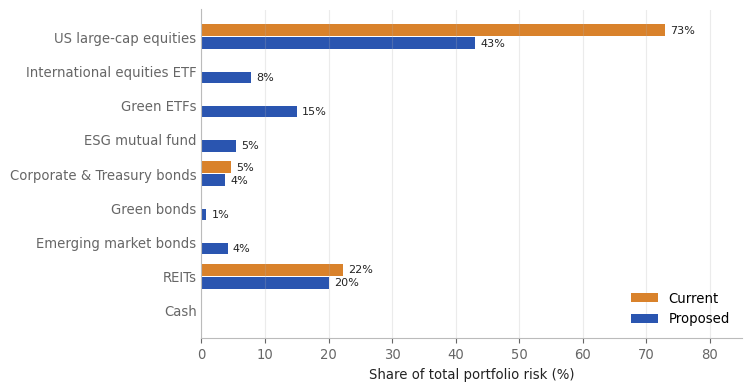

,Current,Proposed
US large-cap equities,73.0,43.1
International equities ETF,0.0,7.8
Green ETFs,0.0,15.0
ESG mutual fund,0.0,5.4
Corporate & Treasury bonds,4.7,3.8
Green bonds,0.0,0.8
Emerging market bonds,0.0,4.1
REITs,22.3,20.0
Cash,0.0,0.0


In [9]:
fig, ax = plt.subplots(figsize=(7.6, 4.0))
y = np.arange(len(ASSETS)); h = 0.38
for vals, off, col, lab in [(rc_cur, -h/2, CUR, "Current"), (rc_pro, h/2, PRO, "Proposed")]:
    bars = ax.barh(y + off, vals, height=h - 0.04, color=col, label=lab)
    for b, v in zip(bars, vals):
        if v > 0.5:
            ax.text(v + 0.8, b.get_y() + b.get_height()/2, f"{v:.0f}%", va="center", fontsize=8, color=INK)
ax.set_yticks(y, ASSETS); ax.invert_yaxis()
ax.set_xlabel("Share of total portfolio risk (%)"); ax.set_xlim(0, 85)
ax.grid(axis="x", alpha=0.25); ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig2_risk_contribution.pdf", bbox_inches="tight")
plt.show()
pd.DataFrame({"Current": rc_cur, "Proposed": rc_pro}).round(1)

## 4. Stress tests

One shock per **recent concern** in the Client Profile (instant moves in %, illustrative).
Core bonds lose less in the proposal because their duration is shortened from ~6 to ~4 years.

In [10]:
shocks = pd.DataFrame({
    "Rates +1 pt":               [-4, -4,  -8, -4, -6, -6, -5,  -8, 0],
    "Equity sell-off":           [-20, -20, -28, -10, 2, 2, -6, -15, 0],
    "Emerging-market crisis":    [-3, -6, -3, -2, 1, 1, -12, -2, 0],
}, index=ASSETS, dtype=float)
# Proposal: shorter-duration core bonds -> smaller loss when rates rise (duration ~4 instead of ~6)
shocks_pro = shocks.copy()
shocks_pro.loc["Corporate & Treasury bonds", "Rates +1 pt"] = -4

stress = pd.DataFrame({
    "Current": (shocks.mul(current, axis=0) / 100).sum(),
    "Proposed": (shocks_pro.mul(proposed, axis=0) / 100).sum(),
})
stress["Difference (pts)"] = stress["Proposed"] - stress["Current"]
stress.round(2)

,Current,Proposed,Difference (pts)
Rates +1 pt,-4.80,-4.54,0.26
Equity sell-off,-10.65,-10.75,-0.10
Emerging-market crisis,-1.35,-2.16,-0.81


In [11]:
lines = [r"\begin{tabular}{@{}lrrr@{}}", r"\toprule",
         r"\textbf{Scenario} & \textbf{Current} & \textbf{Proposed} & \textbf{Difference} \\", r"\midrule"]
for s, r in stress.iterrows():
    lines.append(f"{s} & {tex(r['Current'], '{:.2f}')}\\% & {tex(r['Proposed'], '{:.2f}')}\\% & "
                 f"{tex(r['Difference (pts)'], '{:.2f}', sign=True)} pts \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(FIG / "table3_stress.tex").write_text("\n".join(lines))
print("\n".join(lines))

\begin{tabular}{@{}lrrr@{}}
\toprule
\textbf{Scenario} & \textbf{Current} & \textbf{Proposed} & \textbf{Difference} \\
\midrule
Rates +1 pt & \textminus{}4.80\% & \textminus{}4.54\% & +0.26 pts \\
Equity sell-off & \textminus{}10.65\% & \textminus{}10.75\% & \textminus{}0.10 pts \\
Emerging-market crisis & \textminus{}1.35\% & \textminus{}2.16\% & \textminus{}0.81 pts \\
\bottomrule
\end{tabular}


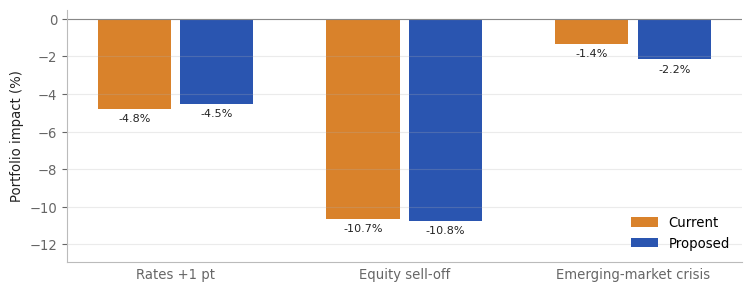

In [12]:
fig, ax = plt.subplots(figsize=(7.6, 3.0))
x = np.arange(len(stress)); w = 0.36
for col_name, off, col in [("Current", -w/2, CUR), ("Proposed", w/2, PRO)]:
    bars = ax.bar(x + off, stress[col_name], width=w - 0.04, color=col, label=col_name)
    for b, v in zip(bars, stress[col_name]):
        ax.text(b.get_x() + b.get_width()/2, v - 0.25, f"{v:.1f}%", ha="center", va="top", fontsize=8, color=INK)
ax.axhline(0, color="#888888", lw=0.8)
ax.set_xticks(x, stress.index); ax.tick_params(axis="x", length=0)
ax.set_ylabel("Portfolio impact (%)"); ax.set_ylim(stress[["Current", "Proposed"]].values.min() - 2.2, 0.5)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig3_stress.pdf", bbox_inches="tight")
plt.show()

## Reading

See the printed tables above: the proposal meets every target in the Client Profile, spreads risk across more holdings,
and changes the loss in each stress scenario as shown. The trade-offs (for example the higher volatility of green ETFs, or
new exposure to emerging-market events) are discussed in the proposal's *Risks* section.